# Feature Extraction


In [1]:
import os, glob, warnings
import numpy as np
import pandas as pd
import scipy.signal
from scipy.signal import find_peaks
from scipy.stats import median_abs_deviation, entropy
import pywt                     # wavelet
import antropy as ent          # sample entropy 
warnings.filterwarnings("ignore")

curfolder = os.getcwd()
processedfolder = os.path.join(curfolder, 'Sapiens_Processed')
kinfiles = glob.glob(os.path.join(processedfolder, '*_kinematics.csv'))
distfiles = glob.glob(os.path.join(processedfolder, '*_distances.csv'))

## Configuration


In [2]:
# sides
SIDES = ["right", "left"]                 # Sapiens uses lowercase

# gross keypoints
ARM_JOINTS = ["shoulder", "elbow", "wrist"]

# aggregate columns 
TOTAL_ARM_SPEED = "arm_total_speed"
TOTAL_ARM_ACC   = "arm_total_acc"
TOTAL_ARM_JERK  = "arm_total_jerk"
TIME_COL        = "time_s"                

# ginfer keypoints
# finger -> {joint role: stem suffix}. MCP=third_joint, PIP=2, DIP=3, TIP=4.
FINGERS = {
    "thumb":         {"MCP": "thumb_third_joint",         "PIP": "thumb2",         "DIP": "thumb3",         "TIP": "thumb4"},
    "index":         {"MCP": "forefinger_third_joint",    "PIP": "forefinger2",    "DIP": "forefinger3",    "TIP": "forefinger4"},
    "middle":        {"MCP": "middle_finger_third_joint", "PIP": "middle_finger2", "DIP": "middle_finger3", "TIP": "middle_finger4"},
    "ring":          {"MCP": "ring_finger_third_joint",   "PIP": "ring_finger2",   "DIP": "ring_finger3",   "TIP": "ring_finger4"},
    "pinky":         {"MCP": "pinky_finger_third_joint",  "PIP": "pinky_finger2",  "DIP": "pinky_finger3",  "TIP": "pinky_finger4"},
}

def kp(side, stem):            # -> "right_forefinger4"
    return f"{side}_{stem}"

def tip_stem(finger):          # -> "forefinger4"
    return FINGERS[finger]["TIP"]

def mcp_stem(finger):
    return FINGERS[finger]["MCP"]

# distance column helper
def dist_col(side, j1, j2):    # "r8_5"  (magnitude column)
    p = "r" if side == "right" else "l"
    return f"{p}{j1}_{j2}"

FINGER_TIP_ID = {"thumb": 4, "index": 8, "middle": 12, "ring": 16, "pinky": 20}
FINGER_MCP_ID = {"thumb": 2, "index": 5, "middle": 9,  "ring": 13, "pinky": 17}  # thumb MCP=2

In [3]:
sample_kin1 = pd.read_csv(kinfiles[2])
sample_dist1 = pd.read_csv(distfiles[2])
sample_kin2 = pd.read_csv(kinfiles[500])
sample_dist2 = pd.read_csv(distfiles[500])

print(sample_kin1["FileID"].iloc[0], sample_kin2["FileID"].iloc[0])
print(sample_dist1["FileID"].iloc[0], sample_dist2["FileID"].iloc[0])

mp4_files = [f for f in os.listdir("GTST_sampled") if f.endswith(".mp4")]
video1 = [f for f in mp4_files if sample_kin1["FileID"].iloc[0] in f][0]
video2 = [f for f in mp4_files if sample_kin2["FileID"].iloc[0] in f][0]

GP01_BLITZ IP08_01_ZEIT
GP01_BLITZ IP08_01_ZEIT


In [5]:
import subprocess
from IPython.display import Video

dst1 = 'Temporary\output1.mp4'  # choose a suitable output path
Video(dst1, width=600, embed=True)

In [6]:
dst2 = 'Temporary\output2.mp4'  # choose a suitable output path
Video(dst2, width=600)

## 1 Gross / arm kinematics  (`*_kinematics.csv`)

These describe the **movement** dimension: magnitude, smoothness, rhythmicity, spatial extent, coordination, and (via the relative-speed columns) proximal-distal ratio.


In [ ]:
# Bounding-box movement volume (spatial extent of a keypoint) 
def get_bbmv(df, side, joint):
    """Area of the x-y bounding box swept by one keypoint = how much space it covers."""
    xc, yc = kp(side, joint) + "_x", kp(side, joint) + "_y"
    if xc not in df.columns or yc not in df.columns:
        return np.nan
    return (df[xc].max() - df[xc].min()) * (df[yc].max() - df[yc].min())

sample_kin1 = pd.read_csv(kinfiles[2])
sample_kin2 = pd.read_csv(kinfiles[500])

print(get_bbmv(sample_kin1, "right", "wrist"))
print(get_bbmv(sample_kin2, "right", "wrist"))

1.0019037357668927
0.2747035042398275


In [ ]:
# Intermittency / dimensionless jerk (smoothness; higher = less smooth)  
def get_intermittency(jerk_values, speed_values):
    """Calculate intermittency (dimensionless jerk) from jerk and speed values.

    Args:
        jerk_values: Array-like of jerk values (acceleration derivative)
        speed_values: Array-like of speed values (velocity magnitude)

    Returns:
        float: Intermittency value (log of sum of squared jerk multiplied by
               (n^3 / max(speed^2)), or NaN if all speeds are zero)
    """
    jerk = np.asarray(jerk_values); speed = np.asarray(speed_values)
    if np.all(speed == 0):
        return np.nan
    return np.log(np.sum(jerk ** 2) * (len(speed) ** 3 / np.max(speed ** 2)))

print(get_intermittency(sample_kin1["right_wrist_jerk"], sample_kin1["right_wrist_speed"]))
print(get_intermittency(sample_kin2["right_wrist_jerk"], sample_kin2["right_wrist_speed"]))


24.49030926487231
23.93417784257083


In [ ]:
# SPARC — spectral arc length smoothness  
# More robust smoothness measure than dimensionless jerk (less noise/duration sensitive).
# More negative = less smooth. Keep alongside intermittency; they disagree usefully.
def get_sparc(speed, fs, fc=10.0, amp_th=0.05):
    """Compute SPARC (Spectral Arc Length Smoothness) metric for motion smoothness.
    Args:
        speed: Array-like of speed values (units: arbitrary)
        fs: Sampling frequency (Hz)
        fc: Cutoff frequency for frequency domain analysis (Hz)
        amp_th: Amplitude threshold for frequency components to include
    Returns:
        SPARC score (more negative = less smooth)
    """
    speed = np.asarray(speed, float)
    if len(speed) < 8 or np.all(speed == 0):
        return np.nan
    N = int(2 ** np.ceil(np.log2(len(speed) * 4)))     # zero-pad for resolution
    Mf = np.abs(np.fft.rfft(speed, N))
    Mf = Mf / (Mf.max() + 1e-12)
    freq = np.fft.rfftfreq(N, d=1.0 / fs)
    keep = freq <= fc
    f, M = freq[keep], Mf[keep]
    inrange = M >= amp_th                                # adaptive cutoff
    if inrange.sum() < 2:
        return np.nan
    f, M = f[inrange], M[inrange]
    df_ = np.diff(f) / (f[-1] - f[0] + 1e-12)
    return -np.sum(np.sqrt(df_ ** 2 + np.diff(M) ** 2))

sr1 = round(len(sample_kin1) / (sample_kin1['time_s'].iloc[-1] - sample_kin1['time_s'].iloc[0]), 0) 
sr2 = round(len(sample_kin2) / (sample_kin2['time_s'].iloc[-1] - sample_kin2['time_s'].iloc[0]), 0) 

print(get_sparc(sample_kin1['right_wrist_speed'], sr1))
print(get_sparc(sample_kin2['right_wrist_speed'], sr2))


-3.1543007006978176
-3.2156258128356714


In [ ]:
# Peaks / submovements   
def compute_peaks(df, col, fs, time_col=TIME_COL):
    """Compute peak characteristics from a signal column in a DataFrame.

    Args:
        df: DataFrame containing the signal data
        col: Name of the column containing the signal
        fs: Sampling frequency of the signal
        time_col: Name of the column containing time values (default: 'time_s')

    Returns:
        Dictionary containing:
        - peak_mean: Mean of peak values
        - peak_std: Standard deviation of peak values
        - peak_n: Number of peaks detected
        - peak_rate: Peak rate (peaks per second)
        - mod_depth: Modulation depth (mean peak - mean trough)
    """
    if col not in df.columns:
        return dict(peak_mean=np.nan, peak_std=np.nan, peak_n=np.nan,
                    peak_rate=np.nan, mod_depth=np.nan)
    scale = median_abs_deviation(df[col].dropna(), scale="normal")
    prominence = scale * 0.6
    distance = int((0.1 if "acc" in col else 0.2) * fs)
    sig = np.abs(df[col].values) if "acc" in col else df[col].values
    peaks, _ = find_peaks(sig, distance=max(distance, 1), prominence=prominence)
    vals = df[col].iloc[peaks]
    duration = df[time_col].iloc[-1] - df[time_col].iloc[0]

    # peak_rate (length-normalized)
    peak_rate = len(peaks) / duration if duration > 0 else np.nan

    # modulation depth = mean(peak) - mean(trough between peaks).
    # Shallow troughs = blended/co-articulated submovements; deep = segmented.
    mod_depth = np.nan
    if len(peaks) >= 2:
        troughs = [sig[peaks[i]:peaks[i+1]].min() for i in range(len(peaks) - 1)]
        mod_depth = float(np.mean(sig[peaks]) - np.mean(troughs))

    return dict(peak_mean=float(vals.mean()) if len(vals) else np.nan,
                peak_std=float(vals.std()) if len(vals) else np.nan,
                peak_n=len(peaks), peak_rate=peak_rate, mod_depth=mod_depth)

TIME_COL = 'time_s'
print(compute_peaks(sample_kin1, 'right_wrist_speed', sr1, TIME_COL))
print(compute_peaks(sample_kin2, 'right_wrist_speed', sr2, TIME_COL))

{'peak_mean': 2.274323216259215, 'peak_std': 0.9399863291251245, 'peak_n': 5, 'peak_rate': 1.056338028169014, 'mod_depth': 1.5773689741508596}
{'peak_mean': 2.242651053828256, 'peak_std': 0.35351138399746607, 'peak_n': 2, 'peak_rate': 0.5042016806722689, 'mod_depth': 2.247108915882587}


In [ ]:
# Bimanual coupling (L<->R correlation) and asymmetry   #
def compute_arm_coupling(df, joints=("wrist", "elbow"), dims=("x", "y"), absolute=True):
    """Compute correlation between left and right arm movements across specified joints and dimensions.

    Args:
        df: DataFrame containing kinematic data with columns named as 'left_{joint}_{dim}' and 'right_{joint}_{dim}'
        joints: Tuple of joint names to analyze (default: wrist and elbow)
        dims: Tuple of dimensions to analyze (default: x and y)
        absolute: If True, return absolute correlation values (default: True)

    Returns:
        Mean correlation between left and right arm movements across specified joints and dimensions,
        or NaN if no valid pairs are found.
    """
    corrs = []
    for j in joints:
        for d in dims:
            lc, rc = f"left_{j}_{d}", f"right_{j}_{d}"
            if lc in df.columns and rc in df.columns:
                c = np.corrcoef(df[lc], df[rc])[0, 1]
                corrs.append(abs(c) if absolute else c)
    return np.nanmean(corrs) if corrs else np.nan

def compute_arm_asymmetry(df):
    """Compute asymmetry between left and right arm movements by comparing absolute speed sums.

    Args:
        df: DataFrame containing kinematic data with columns named as 'left_{joint}_speed' and 'right_{joint}_speed'

    Returns:
        Mean asymmetry between left and right arm movements across all joints,
        where negative values indicate right arm dominance and positive values indicate left arm dominance,
        or NaN if no valid pairs are found.
    """
    diffs = []
    for j in ARM_JOINTS:
        lc, rc = f"left_{j}_speed", f"right_{j}_speed"
        if lc in df.columns and rc in df.columns:
            diffs.append(np.nansum(np.abs(df[lc])) - np.nansum(np.abs(df[rc])))
    return np.nanmean(diffs) if diffs else np.nan

print(compute_arm_coupling(sample_kin1))
print(compute_arm_coupling(sample_kin2))
print(compute_arm_asymmetry(sample_kin1)) 
print(compute_arm_asymmetry(sample_kin2))

0.5436606793067762
0.7500460983811811
-81.55574156097795
6.578552904206847


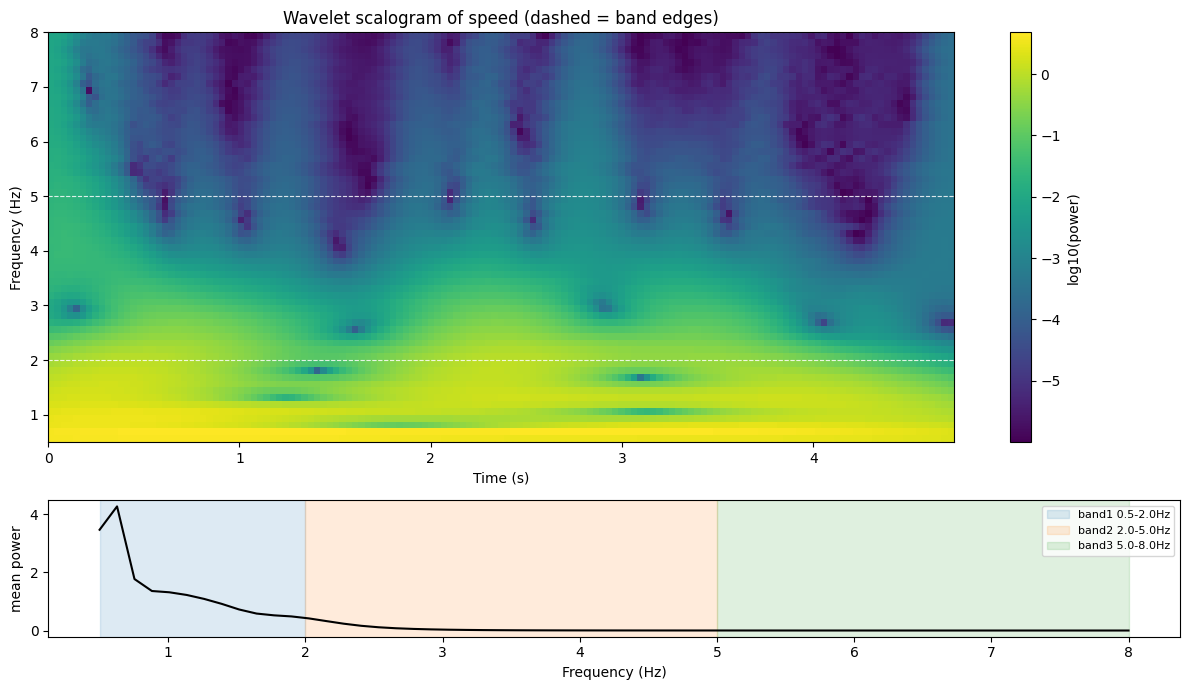

{'band1_dom_freq': 0.6271186440677966, 'band1_centroid': 0.9146233127691183, 'band1_band_power': 0.9194556297641885, 'band1_entropy': 2.236422534968635, 'band2_dom_freq': 2.0254237288135593, 'band2_centroid': 2.3617307916578096, 'band2_band_power': 0.07994137681957933, 'band2_entropy': 2.1356335616423108, 'band3_dom_freq': 5.076271186440678, 'band3_centroid': 5.98590729103482, 'band3_band_power': 0.0005901686610035032, 'band3_entropy': 2.9525230711684283}


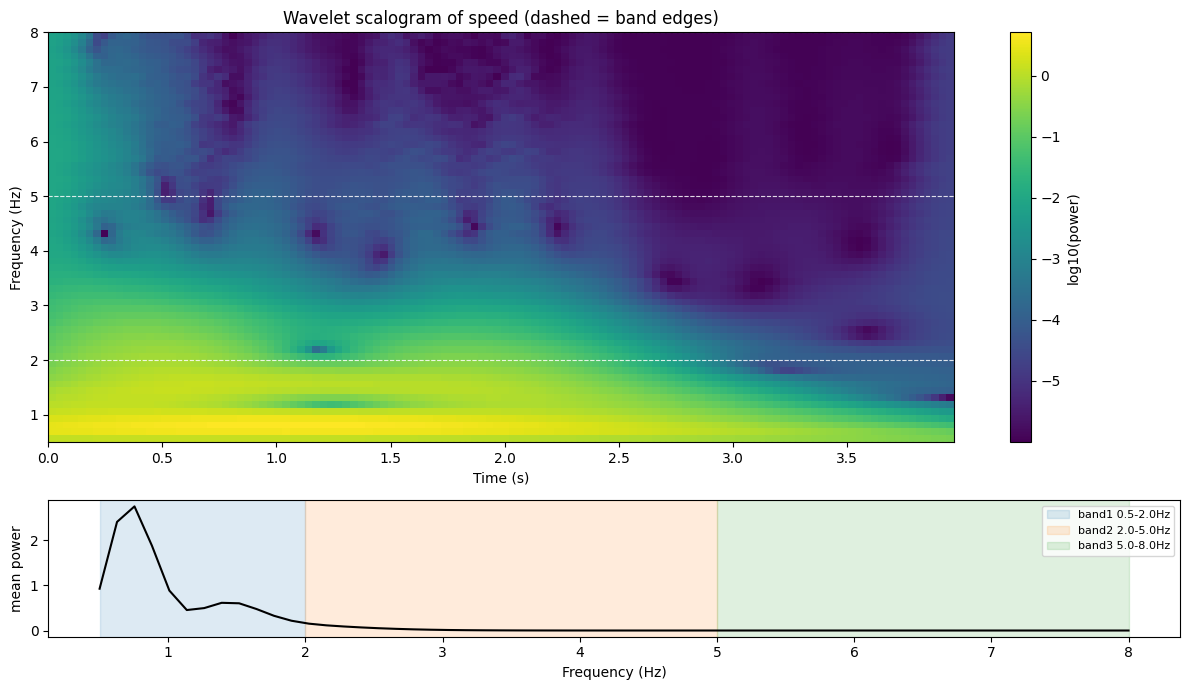

{'band1_dom_freq': 0.7542372881355932, 'band1_centroid': 0.937241166856679, 'band1_band_power': 0.9523881071838445, 'band1_entropy': 2.1935229308456607, 'band2_dom_freq': 2.0254237288135593, 'band2_centroid': 2.35754137884797, 'band2_band_power': 0.04697666629246565, 'band2_entropy': 2.1247790720276387, 'band3_dom_freq': 5.711864406779661, 'band3_centroid': 6.2367554878679465, 'band3_band_power': 0.0006197947925791966, 'band3_entropy': 3.086231721210344}


In [ ]:
# Wavelet rhythmicity (3 bands)  
def wavelet_rhythmicity(speed, time, bands=((0.5,2.0),(2.0,5.0),(5.0,8.0)),
                        n_freqs=60, fs=30, plot=False):
    """Compute wavelet rhythmicity metrics for speed signal.

    Args:
        speed: Input speed signal (array-like)
        time: Time array corresponding to speed (array-like)
        bands: Frequency bands to analyze (list of tuples)
        n_freqs: Number of frequency points to evaluate
        fs: Sampling frequency of input signal
        plot: Whether to generate visualization plots

    Returns:
        Dictionary containing rhythmicity metrics for each band
    """
    out = {}
    speed = np.asarray(speed); time = np.asarray(time)
    dt = np.median(np.diff(time))
    freqs = np.linspace(min(b[0] for b in bands), max(b[1] for b in bands), n_freqs)
    scales = pywt.central_frequency("cmor1.5-1.0") * fs / freqs
    power = np.abs(pywt.cwt(speed, scales, "cmor1.5-1.0", sampling_period=dt)[0]) ** 2

    if plot:
        import matplotlib.pyplot as plt
        fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7),
                                       gridspec_kw={"height_ratios": [3, 1]}, sharex=False)
        # scalogram (time x frequency), log-scaled
        im = ax1.imshow(np.log10(power + 1e-6), aspect="auto", origin="lower",
                        extent=[time[0], time[-1], freqs[0], freqs[-1]], cmap="viridis")
        for (a, b) in bands:                       # mark band boundaries
            ax1.axhline(a, color="w", lw=0.8, ls="--", alpha=0.6)
            ax1.axhline(b, color="w", lw=0.8, ls="--", alpha=0.6)
        fig.colorbar(im, ax=ax1, label="log10(power)")
        ax1.set_ylabel("Frequency (Hz)"); ax1.set_xlabel("Time (s)")
        ax1.set_title("Wavelet scalogram of speed (dashed = band edges)")
        # mean power spectrum with bands shaded
        mp_plot = power.mean(axis=1)
        ax2.plot(freqs, mp_plot, color="k")
        for i, (a, b) in enumerate(bands):
            ax2.axvspan(a, b, alpha=0.15, color=f"C{i}", label=f"band{i+1} {a}-{b}Hz")
        ax2.set_xlabel("Frequency (Hz)"); ax2.set_ylabel("mean power"); ax2.legend(fontsize=8)
        plt.tight_layout(); plt.show()

    mp = power.mean(axis=1); mp /= (mp.sum() + 1e-12)
    for i,(a,b) in enumerate(bands):
        m = (freqs >= a) & (freqs < b); bf, bp = freqs[m], mp[m]
        if len(bp) == 0 or bp.sum() == 0:
            out[f"band{i+1}_dom_freq"]=out[f"band{i+1}_centroid"]=np.nan
            out[f"band{i+1}_band_power"]=0.0; out[f"band{i+1}_entropy"]=np.nan; continue
        p = bp / (bp.sum() + 1e-12)
        out[f"band{i+1}_dom_freq"]  = float(bf[np.argmax(bp)])
        out[f"band{i+1}_centroid"]  = float(np.sum(bf*bp)/np.sum(bp))
        out[f"band{i+1}_band_power"] = float(bp.sum())
        out[f"band{i+1}_entropy"]   = float(-np.sum(p*np.log(p+1e-12)))
    return out

print(wavelet_rhythmicity(sample_kin1['right_wrist_speed'], sample_kin1['time_s'], fs=sr1, plot=True))
print(wavelet_rhythmicity(sample_kin2['right_wrist_speed'], sample_kin2['time_s'], fs=sr2, plot=True))

In [ ]:
# Proximalization index (rel/abs)   
# wrist absolute speed includes elbow transport; wrist relspeed is elbow-removed articulation.
# ratio -> 0 : wrist just carried by the arm (proximalized).  ratio -> 1 : independent forearm
# rotation (distal). Mean over available arm joints that have a relspeed column.
def get_proximalization_index(df):
    """Calculate the proximalization index by computing the ratio of relative to absolute speeds
    for wrist and elbow joints across both sides. Returns the mean ratio or NaN if no valid data."""
    ratios = []
    for side in SIDES:
        for j in ("wrist", "elbow"):
            ab, rel = f"{side}_{j}_speed", f"{side}_{j}_relspeed"
            if ab in df.columns and rel in df.columns:
                a = df[ab].to_numpy(); r = df[rel].to_numpy()
                denom = np.nanmedian(a)
                if denom > 1e-9:
                    ratios.append(np.nanmedian(r) / denom)
    return np.nanmean(ratios) if ratios else np.nan

print(get_proximalization_index(sample_kin1))
print(get_proximalization_index(sample_kin2))


0.7505159769423924
1.0266483604393912


## 2 Hand / handshape features  (`*_hand_distances.csv` + finger cols of kinematics)

Here we calculate handshape geometry a finger independence.

In [ ]:
# Handshape geometry from distance columns   
def feature_adjacent_fingertip_spread(df, side):
    """Mean & std of adjacent fingertip gaps (thumb-index, index-middle, ...)."""
    cols = [dist_col(side, 4, 8), dist_col(side, 8, 12),
            dist_col(side, 12, 16), dist_col(side, 16, 20)]
    cols = [c for c in cols if c in df.columns]
    if not cols: return np.nan, np.nan
    return df[cols].mean().mean(), df[cols].mean().std()

def feature_thumb_index_distance(df, side):                # aperture / pinch
    """Calculate mean and standard deviation of thumb-index distance."""
    c = dist_col(side, 4, 8)
    return (df[c].mean(), df[c].std()) if c in df.columns else (np.nan, np.nan)

def feature_mcp_tip_distance(df, side):                     # overall flexion (tip->MCP)
    """Mean & std of MCP-tip distances (thumb, index, middle, ring, pinky)."""
    cols = [dist_col(side, FINGER_TIP_ID[f], FINGER_MCP_ID[f])
            for f in ["thumb","index","middle","ring","pinky"]]
    cols = [c for c in cols if c in df.columns]
    if not cols: return np.nan, np.nan
    return df[cols].mean().mean(), df[cols].mean().std()

# thumb opposition — thumb tip to pinky MCP (a distinct phonological handshape axis)
def feature_thumb_opposition(df, side):
    """Calculate mean and standard deviation of thumb tip to pinky MCP distance."""
    c = dist_col(side, 4, FINGER_MCP_ID["pinky"])
    return (df[c].mean(), df[c].std()) if c in df.columns else (np.nan, np.nan)

# spread
print(feature_adjacent_fingertip_spread(sample_dist1, "right"))
print(feature_adjacent_fingertip_spread(sample_dist2, "right"))

# thumb-index distance
print(feature_thumb_index_distance(sample_dist1, "right"))
print(feature_thumb_index_distance(sample_dist2, "right"))

# mcp-tip distance
print(feature_mcp_tip_distance(sample_dist1, "right"))
print(feature_mcp_tip_distance(sample_dist2, "right"))

# thumb opposition
print(feature_thumb_opposition(sample_dist1, "right"))
print(feature_thumb_opposition(sample_dist2, "right"))

(0.5048154548984572, 0.19657274624848997)
(1.0351736387080717, 0.43178428586762296)
(0.788639984984575, 0.48350163717173905)
(1.598669357714077, 0.6238947739492059)
(1.0625774464749411, 0.1501563051966416)
(1.9770988162529217, 0.5297526771844618)
(1.7457688367172848, 0.27045368610782294)
(2.9820161359059587, 0.5487910879083462)


In [ ]:
# Handshape size & variability  
def feature_handshape_size(df, side):
    """Calculate mean and standard deviation of handshape features."""
    p = "r" if side == "right" else "l"
    cols = [c for c in df.columns
            if c.startswith(p) and "_" in c
            and not c.endswith(("_x","_y","_speed","_acc","_jerk"))
            and df[c].dtype != object]
    if not cols: return np.nan, np.nan
    return df[cols].mean(axis=1).mean(), df[cols].std(axis=1).mean()

def feature_handshape_variability(df, side):
    """Total temporal SD of the adjacent-fingertip gaps = how much handshape changes."""
    cols = [dist_col(side, 4, 8), dist_col(side, 8, 12),
            dist_col(side, 12, 16), dist_col(side, 16, 20)]
    cols = [c for c in cols if c in df.columns]
    return df[cols].std().sum() if cols else np.nan

# handshape size
print("handshape size")
print(feature_handshape_size(sample_dist1, "right"))
print(feature_handshape_size(sample_dist2, "right"))

# handshape variability
print("handshape variability")
print(feature_handshape_variability(sample_dist1, "right"))
print(feature_handshape_variability(sample_dist2, "right"))


handshape size
(5.553572068576557, 10.674141951239658)
(6.406650059953085, 15.549440361437341)
handshape variability
1.119664366666655
2.142825952902557


In [ ]:
# Fingertip dynamics 

def _tip_mcp_speed_cols(df, side):
    """Identifies and returns columns in the DataFrame that contain speed data between fingertip and MCP joints for specified fingers (excluding thumb)."""
    cols = [f"{dist_col(side, FINGER_TIP_ID[f], FINGER_MCP_ID[f])}_speed"
            for f in ["index","middle","ring","pinky"]]     # thumb handled separately
    return [c for c in cols if c in df.columns]

def feature_fingertip_speed(df, side):                      
    """Calculates the mean and standard deviation of fingertip speed between MCP and fingertip joints for specified fingers (excluding thumb)."""
    cols = _tip_mcp_speed_cols(df, side)
    if not cols: return np.nan, np.nan
    return df[cols].mean().mean(), df[cols].mean().std()

def feature_fingertip_jerk(df, side):
    """Calculates the mean of fingertip jerk between MCP and fingertip joints for specified fingers (excluding thumb)."""
    cols = [c.replace("_speed", "_jerk") for c in _tip_mcp_speed_cols(df, side)]
    cols = [c for c in cols if c in df.columns]
    return df[cols].mean().mean() if cols else np.nan

print("fingertip speed")
print(feature_fingertip_speed(sample_dist1, "right"))
print(feature_fingertip_speed(sample_dist2, "right"))

print("fingertip jerk")
print(feature_fingertip_jerk(sample_dist1, "right"))
print(feature_fingertip_jerk(sample_dist2, "right"))

fingertip speed
(1.3414553538645329, 0.14441469082567054)
(2.305640770462585, 0.24977141911922052)
fingertip jerk
-2.617639170008474
5.668087607140037


In [ ]:
# Finger independence   
# Correlate FLEXION speeds (tip->MCP distance speed), which have wrist motion removed.
# independence = 1 - mean pairwise corr.  High = fingers move independently (native-signer-like).
def feature_finger_independence(df, side):
    pairs = [("index","middle"), ("middle","ring"), ("ring","pinky")]
    corrs = []
    for a, b in pairs:
        ca = f"{dist_col(side, FINGER_TIP_ID[a], FINGER_MCP_ID[a])}_speed"
        cb = f"{dist_col(side, FINGER_TIP_ID[b], FINGER_MCP_ID[b])}_speed"
        if ca in df.columns and cb in df.columns:
            corrs.append(df[ca].corr(df[cb]))
    return 1 - np.nanmean(corrs) if corrs else np.nan

print("finger indepenedence")
print(feature_finger_independence(sample_dist1, "right"))
print(feature_finger_independence(sample_dist2, "right"))

finger indepenedence
0.15094077555764995
0.12736945205958472
finger speed correlation
0.809712349760017
0.7091644224819295


In [ ]:
# Speed entropy of finger flexion (variability of the signal)   
def feature_finger_speed_entropy(df, side, finger="index"):
    """Calculate the entropy of finger speed variability from distance data."""
    c = f"{dist_col(side, FINGER_TIP_ID[finger], FINGER_MCP_ID[finger])}_speed"
    if c not in df.columns: return np.nan
    hist, _ = np.histogram(df[c].dropna(), bins=30, density=True)
    return entropy(hist + 1e-8)

print(feature_finger_speed_entropy(sample_dist1, "right"))
print(feature_finger_speed_entropy(sample_dist2, "right"))

3.1381879883958805
2.2097272568763615


## 3 Per-file assembly

`extract_gross_features` and `extract_hand_features` each return a flat dict; `extract_all` merges them for one file. 

In [ ]:
def _mean_sides(fn, *dfs):
    """Call fn(*dfs, side) for each side, return nan-mean of the (scalar or tuple) results.
    Handles fns that return a scalar OR a (mean, std) tuple -> returns pooled scalar/tuple."""
    vals = [fn(*dfs, side) for side in SIDES]
    if isinstance(vals[0], tuple):
        return tuple(np.nanmean([v[i] for v in vals]) for i in range(len(vals[0])))
    return np.nanmean(vals)


def fname(name: str, domain: str, family: str) -> str:
    """Format a feature column name as domain__family__name."""
    return f"{domain}__{family}__{name}"

def extract_gross_features(df, fs):
    f = {}
    # aggregate arm-speed descriptives (uses your total_arm_* columns)
    for col, tag in [(TOTAL_ARM_SPEED, "arm_speed"), (TOTAL_ARM_ACC, "arm_acc")]:
        if col in df.columns:
            f[fname(f"{tag}_Gmean", "gross", "magnitude")]   = df[col].mean()
            f[fname(f"{tag}_Gstd",  "gross", "variability")] = df[col].std()
            pk = compute_peaks(df, col, fs)
            f[fname(f"{tag}_peak_mean", "gross", "magnitude")]   = pk["peak_mean"]
            f[fname(f"{tag}_peak_std",  "gross", "variability")] = pk["peak_std"]
            f[fname(f"{tag}_peak_n",    "gross", "rhythm")]      = pk["peak_n"]
            f[fname(f"{tag}_peak_rate", "gross", "rhythm")]      = pk["peak_rate"]
            f[fname(f"{tag}_mod_depth", "gross", "rhythm")]      = pk["mod_depth"]
    # integral / smoothness / rhythm on the total_arm signal
    if TOTAL_ARM_SPEED in df.columns:
        f[fname("arm_speed_integral", "gross", "magnitude")] = np.trapz(df[TOTAL_ARM_SPEED].values, dx=1/fs)
        f[fname("arm_speed_sampen", "gross", "rhythm")] = ent.sample_entropy(df[TOTAL_ARM_SPEED].values, order=2)
        f[fname("arm_intermittency", "gross", "smoothness")] = get_intermittency(
            df.get(TOTAL_ARM_JERK, pd.Series(dtype=float)), df[TOTAL_ARM_SPEED])
        f[fname("arm_sparc", "gross", "smoothness")] = get_sparc(df[TOTAL_ARM_SPEED].values, fs)
        for k, v in wavelet_rhythmicity(df[TOTAL_ARM_SPEED], df[TIME_COL], fs=fs).items():
            f[fname(f"{k}_totalarm", "gross", "rhythm")] = v

    # BBMV
    bbmv_total = np.nansum([get_bbmv(df, side, j) for side in SIDES for j in ARM_JOINTS])
    f[fname("bbmv_arms_total", "gross", "magnitude")] = bbmv_total

    # coordination — intrinsically bilateral, computed once (NOT side-averaged)
    f[fname("arm_coupling",  "gross", "coordination")] = compute_arm_coupling(df)
    f[fname("arm_asymmetry", "gross", "coordination")] = compute_arm_asymmetry(df)
    f[fname("proximalization_index", "gross", "proxdist")] = get_proximalization_index(df)  # already means over sides internally
    return f


def extract_hand_features(df_kin, df_dist):
    f = {}
    # geometry / handshape: mean over L and R ---
    m, sd = _mean_sides(feature_adjacent_fingertip_spread, df_dist)
    f[fname("fingertip_spread_mean", "fine", "handshape")]   = m
    f[fname("fingertip_spread_std",  "fine", "variability")] = sd

    m, sd = _mean_sides(feature_thumb_index_distance, df_dist)
    f[fname("thumb_index_mean", "fine", "handshape")]   = m
    f[fname("thumb_index_std",  "fine", "variability")] = sd

    m, sd = _mean_sides(feature_mcp_tip_distance, df_dist)
    f[fname("mcp_tip_mean", "fine", "handshape")]   = m
    f[fname("mcp_tip_std",  "fine", "variability")] = sd

    m, sd = _mean_sides(feature_thumb_opposition, df_dist)
    f[fname("thumb_opposition_mean", "fine", "handshape")]   = m
    f[fname("thumb_opposition_std",  "fine", "variability")] = sd

    m, sd = _mean_sides(feature_handshape_size, df_dist)
    f[fname("handshape_size_mean", "fine", "handshape")]   = m
    f[fname("handshape_size_std",  "fine", "variability")] = sd

    f[fname("handshape_variability", "fine", "variability")] = np.nanmean(
        [feature_handshape_variability(df_dist, side) for side in SIDES])

    # dynamics (gross-independent): mean over L and R 
    m, sd = _mean_sides(feature_fingertip_speed, df_dist)
    f[fname("flexion_speed_mean", "fine", "magnitude")]   = m
    f[fname("flexion_speed_std",  "fine", "variability")] = sd

    f[fname("flexion_jerk", "fine", "smoothness")] = np.nanmean(
        [feature_fingertip_jerk(df_dist, side) for side in SIDES])

    # coordination — average the two hands' independence/correlations 
    f[fname("finger_independence", "fine", "coordination")] = np.nanmean(
        [feature_finger_independence(df_dist, side) for side in SIDES])

    f[fname("flexion_entropy", "fine", "variability")] = np.nanmean(
        [feature_finger_speed_entropy(df_dist, side, "index") for side in SIDES])
    return f

def extract_all(df_kin, df_dist, fs):
    return {**extract_gross_features(df_kin, fs), **extract_hand_features(df_kin, df_dist)}

## 4 Batch loop

In [ ]:
processedfolder = os.path.join(curfolder, "Sapiens_Processed")   # <-- set curfolder above
datasetsfolder  = os.path.join(curfolder, "Datasets")

kin_files = sorted(glob.glob(os.path.join(processedfolder, "*_kinematics.csv")))

rows = []
for kin_file in kin_files:
    print("processing", os.path.basename(kin_file))

    dist_file = kin_file.replace("_kinematics.csv", "_hand_distances.csv")
    if not os.path.exists(dist_file):
        print("no distance file for", os.path.basename(kin_file)); continue

    df_kin  = pd.read_csv(kin_file)
    df_dist = pd.read_csv(dist_file)
    fid = df_kin["FileID"].iloc[0]

    # skip practice trials
    # if any(t in fid for t in ("LIGHTNING", "TO-HEAR", "GOAL")):
    #     continue

    fs = round(len(df_kin) / (df_kin[TIME_COL].iloc[-1] - df_kin[TIME_COL].iloc[0]))

    feats = extract_all(df_kin, df_dist, fs)
    feats["fileID"] = fid

    # group identification
    if "GtST" in fid:
        feats["group"] = fid.split("_")[0]
        feats["groupID"] = 'Sign'
    elif 'GP' in fid:
        feats["group"] = fid.split("_")[0]
        feats["groupID"] = 'Gesture'
    elif fid.startswith("LP") or fid.startswith("IP"):
        feats["group"] = "_".join(fid.split("_")[:2])
        if "_01_" in fid:
            feats["groupID"] = 'Learner_1'
        elif "_02_" in fid:
            feats["groupID"] = 'Learner_2'
        else:
            print('error')
            break

    elif "ViCom" in fid:
        feats["group"] = "ViCom"
        feats["groupID"] = "Sign"
    else:
        print("unparsed fileID:", fid); continue

    # concept
    try:
        if "GtST" in fid:   feats["concept"] = fid.split("_")[2].split(".")[0]
        elif "GP" in fid:   feats["concept"] = fid.split("_")[1].split(".")[0]
        elif "LP" in fid or "IP" in fid: feats["concept"] = fid.split("_")[2].split(".")[0]
        elif "ViCom" in fid: feats["concept"] = fid.split("_")[3].split(".")[0]
    except IndexError:
        feats["concept"] = np.nan
    fix = {"TO-PICK":"TO-PLUCK", "TO-MOVE-HOUSES":"TO-MOVE", "VIDEO-GAME":"VIDEOGAME"}
    feats["concept"] = fix.get(feats.get("concept"), feats.get("concept"))

    rows.append(feats)

features_df = pd.DataFrame(rows)
print(features_df.shape, "->", features_df["group"].value_counts().to_dict() if len(features_df) else "empty")

features_df['pcnID'] = features_df['group'].str.split("_").str[0]

features_df.to_csv(os.path.join(datasetsfolder, "sapiens_features.csv"), index=False)

processing GP01_ADLER_kinematics.csv
processing GP01_ANSTECKEN_kinematics.csv
processing GP01_BLITZ_kinematics.csv
processing GP01_BODEN_kinematics.csv
processing GP01_BRIEF_kinematics.csv
processing GP01_BUERO_kinematics.csv
processing GP01_ENTSCHULDIGEN_kinematics.csv
processing GP01_GEIGE_kinematics.csv
processing GP01_GIRAFFE_kinematics.csv
processing GP01_GOTT_kinematics.csv
processing GP01_HEMD_kinematics.csv
processing GP01_KLOPFEN_kinematics.csv
processing GP01_MENSCH_kinematics.csv
processing GP01_RUFEN_kinematics.csv
processing GP01_SCHOKOLADE_kinematics.csv
processing GP01_STAUBSAUGEN_kinematics.csv
processing GP01_WENIG_kinematics.csv
processing GP02_ABLEHNEN_kinematics.csv
processing GP02_ANTWORTEN_kinematics.csv
processing GP02_FENSTER_kinematics.csv
processing GP02_GEHOERLOS_kinematics.csv
processing GP02_GITARRE_kinematics.csv
processing GP02_GUT_kinematics.csv
processing GP02_IGNORIEREN_kinematics.csv
processing GP02_MUSIK_kinematics.csv
processing GP02_PARKEN_kinemati

## 5 Aftermath

In [ ]:
# check missing values
nan_pct = features_df.isna().mean().mul(100).round(1).sort_values(ascending=False)
print("features >50% NaN (check names in §0):")
print(nan_pct[nan_pct > 50])

In [121]:
features_df_clean = features_df[~features_df['group'].str.startswith('LP')]
features_df_clean.to_csv(os.path.join(datasetsfolder, "sapiens_features_noLP.csv"), index=False)

In [ ]:
# Keep only those sampled within no-concept randomization

noconcept = pd.read_csv('sampled_files_noconcept.csv', index_col=0)
noconcept['filename'] = noconcept['file'].replace(" .mp4", "", regex=True)
noconcept['filename'] = noconcept['file'].replace(".mp4", "", regex=True)

features_df_NC = features_df[features_df['fileID'].isin(noconcept['filename'])]
features_df_NC

features_df_NC_clean = features_df_NC[~features_df_NC['group'].str.startswith('LP')]
features_df_NC_clean.to_csv(os.path.join(datasetsfolder, "sapiens_features_noconcept_noLP.csv"), index=False)

## 6 UMAP

In [ ]:
import plotly.express as px, pandas as pd, umap
from sklearn.preprocessing import StandardScaler

feat_df = features_df_clean.copy()

meta_cols = ['fileID', 'group', 'concept', 'groupID']        # add meta columns
meta_cols = [c for c in meta_cols if c in feat_df.columns]

num = feat_df.select_dtypes('number')
num = num.loc[:, num.isna().mean() < 0.5]         # keep cols <50% NaN

keep = num.dropna().index                          
num  = num.loc[keep]
meta = feat_df.loc[keep, meta_cols]              

scaled   = StandardScaler().fit_transform(num)
embedding = umap.UMAP(random_state=42).fit_transform(scaled)

plot_df = pd.DataFrame(embedding, columns=['x', 'y'], index=keep)
plot_df = pd.concat([plot_df, meta], axis=1)       # aligned by index, not by position

fig = px.scatter(plot_df, x='x', y='y',
                 color='groupID' if 'groupID' not in plot_df else 'groupID',
                 symbol='group', hover_name='concept',
                 title='UMAP projection', opacity=0.6)
fig.update_layout(width=900, height=800, yaxis=dict(scaleanchor='x', scaleratio=1))
fig.show()